# OAI 5G uplink captures in SigMF — what is in the data, and how to train a receiver on it

**Run:** `v3_g16_mcs9_classical` — 60 uplink PUSCH slots recorded simultaneously at the gNB and the UE
(OAI 5G SA, 2× Jetson AGX Orin, 2× USRP B210, NI data-recording app + OAI T-Tracer, 18 Nov 2026).

This notebook is a guided tour. It:

1. explains what each of the seven SigMF streams is and where it sits in the 5G NR uplink chain,
2. shows four **format quirks** you have to handle before the data is usable (each one is proven on the data),
3. runs tasks 1–7 of the task list using the modules in this folder,
4. ends with **how to use this data to train a neural receiver**, and what is still missing.

### Main findings for this run

| | |
|---|---|
| Records | 60/60 complete, SHA-512 verified, frame/slot/RNTI agree on gNB and UE |
| Configuration | MCS 9 (QPSK, R≈0.66), 6 PRB = 72 subcarriers, 13 symbols, DMRS type 1 at symbols 0/5/10, 1 Rx antenna |
| Payload | 1128 bits/slot (= TBS for this allocation), 1656 coded bits/slot = 828 data REs × 2 |
| Decoding | 0 payload bit errors and 0 coded-bit errors (BER < 4.4e-5 at 95 % confidence) |
| Receiver | **classical** (interpolated CE populated in 100 % of records; matches metadata) |
| SNR | channel ≈ **26.2 dB**; after the gNB's own channel estimate only ≈ **20.8 dB** → ~5 dB lost in classical CE |
| Channel | flat over 2.16 MHz (delay spread not resolvable at 6 PRB), no measurable Doppler, residual CFO ≈ −73 Hz, timing offset ≈ −107 ns |
| Python reference RX | 0 coded-bit errors, post-eq SNR 24.9 dB (≈4 dB better than the gNB's interpolation) |

**Format quirks the loader handles:** symbol-major storage · data REs packed in DMRS symbols ·
bits stored LSB-first per byte · `tx-pilots-fd-data` is the *transmitted* DMRS, not the received one.

In [1]:
import json, glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

import dsp
from sigmf_loader import load_run, resolve_run, summarize, records_to_frame

RUN = "data/v3_g16_mcs9_classical.zip"   # a run folder works too
FOLDER = resolve_run(RUN)                 # unzips to a temp dir if needed
print(FOLDER)

/tmp/sigmf_runs/v3_g16_mcs9_classical/v3_g16_mcs9_classical


## Part A — What is in the folder

### A.1 Files

Every stream is a SigMF pair: a `.sigmf-meta` JSON (what the samples mean) and a `.sigmf-data` raw binary
(the samples). A `.sigmf-collection` per record ties the seven streams of one slot together, and
`config_data_recording_app.json` is the recorder configuration.

In [2]:
files = sorted(os.listdir(FOLDER))
kind = pd.Series([f.split("-rec-")[0] + "  ." + f.rsplit(".", 1)[-1] if "-rec-" in f else f for f in files])
kind.value_counts().sort_index().to_frame("files")

,files
config_data_recording_app.json,1
data-collection .sigmf-collection,60
raw-ce-fd-data .sigmf-data,60
raw-ce-fd-data .sigmf-meta,60
raw-inter-ce-fd-data .sigmf-data,60
raw-inter-ce-fd-data .sigmf-meta,60
rx-fd-data .sigmf-data,60
rx-fd-data .sigmf-meta,60
rx-payload-bits .sigmf-data,60
rx-payload-bits .sigmf-meta,60


### A.2 Where each stream sits in the uplink chain

```
 UE                                                                             gNB
 payload bits ─► CRC ─► LDPC ─► rate-match ─► scramble ─► QPSK ─► RE map ─► OFDM ─► RF ─► FFT ─► channel est. ─► interp ─► equalize ─► LLR ─► descramble ─► LDPC dec ─► payload bits
 [tx-payload-bits]                          [tx-scrambled-bits]      (+DMRS [tx-pilots])  [rx-fd-data]  [raw-ce]      [raw-inter-ce]                                [rx-payload-bits]
```

| stream | side | what it physically is | role for ML |
|---|---|---|---|
| `rx-fd-data` | gNB | received resource grid after FFT, **data REs only** | **input** |
| `raw-ce-fd-data` | gNB | least-squares channel estimate at DMRS REs (y_p / x_p) | **input** (carries the pilot information) |
| `raw-inter-ce-fd-data` | gNB | classical estimate interpolated to all data REs | baseline only — absent under the AI receiver |
| `tx-pilots-fd-data` | gNB | the DMRS sequence the UE was told to send (*reference*, not received) | pilot positions / values |
| `tx-scrambled-bits` | UE | coded + scrambled bits = exactly what was mapped onto the REs | **label** (per-RE bits → LLR training) |
| `tx-payload-bits` | UE | transport block before CRC/LDPC | ground truth for end-to-end BER |
| `rx-payload-bits` | gNB | what the gNB decoded | compare with `tx-payload-bits` |

The key point for training: `tx-scrambled-bits` are the bits **on the air**, so each data RE has exactly
`Qm` known label bits. A neural receiver can be trained to output LLRs per RE with a binary cross-entropy loss
against these labels, and then plugged into the normal descrambler + LDPC decoder.

### A.3 One `.sigmf-meta`, abbreviated

In [3]:
meta_path = glob.glob(os.path.join(FOLDER, "rx-fd-data-rec-0-*.sigmf-meta"))[0]
meta = json.load(open(meta_path))
g = dict(meta["global"]); g["core:sha512"] = g["core:sha512"][:16] + "…"
print(json.dumps({"global": g, "captures": meta["captures"]}, indent=1))
ann = meta["annotations"][0]
print("annotation keys:", list(ann))
print("\nchannel (emulator CONFIG, not a measurement):", json.dumps(ann["system_components:channel"][0]))
print("\n5G NR parameters:")
print(json.dumps(ann["system_components:transmitter"][0]["signal:detail"]["5gnr"], indent=1))

{
 "global": {
  "core:author": "Abdo Gaber",
  "core:collection": "data-collection-rec-0-2026_11_18T13_57_23_001",
  "core:dataset": "rx-fd-data-rec-0-2026_11_18T13_57_23_001.sigmf-data",
  "core:datatype": "cf32_le",
  "core:description": "Frequency-domain RX data",
  "core:hw": "USRP B210",
  "core:license": "MIT License",
  "core:num_channels": 1,
  "core:recorder": "NI Data Recording Application for OAI",
  "core:sample_rate": 15360000.0,
  "core:sha512": "fcb2ea4ded111117\u2026",
  "core:version": "1.2.1"
 },
 "captures": [
  {
   "core:datetime": "2026_11_18T13:57:23.001",
   "core:frequency": 3604800000.0,
   "core:sample_start": 0,
   "serialization:counts": [
    72,
    13
   ],
   "serialization:scheme": [
    "subcarriers",
    "ofdm_symbols"
   ]
  }
 ]
}
annotation keys: ['core:sample_count', 'core:sample_start', 'num_transmitters', 'system_components:channel', 'system_components:receiver', 'system_components:transmitter']

channel (emulator CONFIG, not a measurement): {

### A.4 Checking the sizes against 3GPP

* 6 PRB × 12 = **72 subcarriers**; PUSCH mapping type B, 13 symbols from symbol 0.
* DMRS type 1, 1 symbol long, 2 additional positions → DMRS in symbols **0, 5, 10** on the even subcarriers
  (CDM group 0). The odd subcarriers of those symbols still carry data.
* Data REs = 10 × 72 + 3 × 36 = **828** → × Qm = 2 → **1656 coded bits** ✔ (`tx-scrambled-bits` length)
* TBS from TS 38.214 §5.1.3.2 below ✔ (`tx-payload-bits` length 1128)

In [4]:
# TS 38.214 5.1.3.2 transport-block size for this allocation (MCS table 1, index 9: Qm=2, R=679/1024)
n_prb, n_sym, dmrs_re_per_prb, Qm, R, v = 6, 13, 3 * 6, 2, 679 / 1024, 1
n_re_prime = 12 * n_sym - dmrs_re_per_prb      # 12*13 - 18 = 138  (DMRS CDM group 0 only: 6 REs/PRB/symbol)
N_re = min(156, n_re_prime) * n_prb             # 828
N_info = N_re * R * Qm * v
n = max(3, int(np.floor(np.log2(N_info))) - 6)
N_info_p = max(24, 2 ** n * int(np.floor(N_info / 2 ** n)))
tbs_table = [24,32,40,48,56,64,72,80,88,96,104,112,120,128,136,144,152,160,168,176,184,192,208,224,240,256,272,288,
             304,320,336,352,368,384,408,432,456,480,504,528,552,576,608,640,672,704,736,768,808,848,888,928,984,
             1032,1064,1128,1160,1192,1224,1256,1288,1320,1352,1416,1480,1544,1608,1672,1736,1800,1864,1928,2024]
TBS = min(t for t in tbs_table if t >= N_info_p)
print(f"N_RE={N_re}  coded bits={N_re*Qm}  N_info={N_info:.0f}  N'_info={N_info_p}  TBS={TBS}")

N_RE=828  coded bits=1656  N_info=1098  N'_info=1088  TBS=1128


## Part B — Four format quirks (and the proof for each)

Naively reading the files gives a scrambled grid and a coded BER of 50 %. These are the four reasons.

### B.1 The grids are stored symbol-major
`serialization:counts = [72, 13]` with scheme `[subcarriers, ofdm_symbols]`, but the samples run through
all 72 subcarriers of symbol 0 first, then symbol 1, … — i.e. **Fortran order** for that shape.
Proof: the DMRS reference must be non-zero on every other subcarrier of exactly three symbols.

In [5]:
raw = np.fromfile(glob.glob(os.path.join(FOLDER, "tx-pilots-fd-data-rec-0-*.sigmf-data"))[0], "<c8")
C_order = raw.reshape(72, 13)            # naive
F_order = raw.reshape(72, 13, order="F") # symbol-major
print("non-zero REs per OFDM symbol, naive C-order :", (C_order != 0).sum(0))
print("non-zero REs per OFDM symbol, symbol-major  :", (F_order != 0).sum(0))
print("DMRS subcarriers in symbol 0:", np.nonzero(F_order[:, 0])[0][:10], "…")
print("DMRS I/Q values:", np.unique(F_order[F_order != 0].real), "-> |x| = 32767: int16 full scale, 2^15/sqrt(2) per I/Q")

non-zero REs per OFDM symbol, naive C-order : [9 8 9 7 9 8 9 7 9 8 9 8 8]
non-zero REs per OFDM symbol, symbol-major  : [36  0  0  0  0 36  0  0  0  0 36  0  0]
DMRS subcarriers in symbol 0: [ 0  2  4  6  8 10 12 14 16 18] …
DMRS I/Q values: [-23170.  23170.] -> |x| = 32767: int16 full scale, 2^15/sqrt(2) per I/Q


### B.2 In DMRS symbols the data REs are *packed*
In symbols 0/5/10 only the 36 odd subcarriers carry data, but the gNB writes them into rows **0–35**
and leaves rows 36–71 zero (the black blocks in the left heatmap). The proof: in the interpolated channel
estimate, the packed value in row *i* of symbol 0 equals the value at odd subcarrier *2i+1* of the
neighbouring data symbol — exactly (ratio 1.000).

rows non-zero in stored symbol 0: [ 0 35]
stored ce sym0 rows 0..5 / ce sym1 odd sc 1,3..11: [1.-0.j 1.-0.j 1.-0.j 1.-0.j 1.-0.j 1.-0.j]


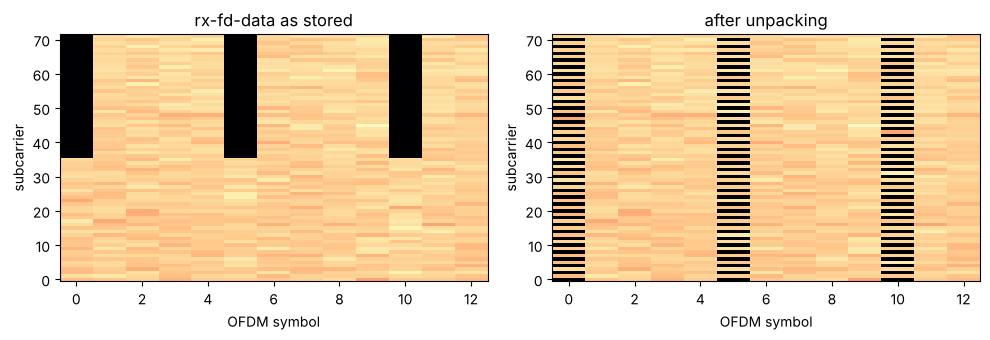

In [6]:
recs = load_run(RUN)
r = recs[0]
hs, hi = r["ce_interp_stored"], r["ce_interp"]
print("rows non-zero in stored symbol 0:", np.nonzero(r["rx_grid_stored"][:, 0])[0][[0, -1]])
print("stored ce sym0 rows 0..5 / ce sym1 odd sc 1,3..11:", np.round((hs[:6, 0] / hs[1:12:2, 1]), 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, g_, t in [(ax[0], r["rx_grid_stored"], "rx-fd-data as stored"), (ax[1], r["rx_grid"], "after unpacking")]:
    a.imshow(20*np.log10(np.abs(g_) + 1e-3), aspect="auto", origin="lower", cmap="magma", vmin=25)
    a.set_title(t); a.set_xlabel("OFDM symbol"); a.set_ylabel("subcarrier"); a.grid(False)
plt.tight_layout()

### B.3 Bit streams are one bit per byte, but LSB-first within every 8 bits
`ri8_le` with one 0/1 value per byte. Comparing hard decisions of the gNB-equalized constellation with
`tx-scrambled-bits`: as stored → BER ≈ 0.5 (random); after reversing each group of 8 → **BER = 0**.
(The payload streams are reversed the same way; their tx-vs-rx BER does not depend on it.)

In [7]:
raw_lab = np.fromfile(glob.glob(os.path.join(FOLDER, "tx-scrambled-bits-rec-0-*.sigmf-data"))[0], "i1")
z, _ = dsp.equalize(r)                                 # gNB grid / gNB interpolated CE, 3GPP RE order
hard = dsp.hard_bits(dsp.qpsk_llr(z, 1.0))
print("BER vs labels as stored        :", np.mean(hard != raw_lab))
print("BER vs labels, 8-bit reversed  :", np.mean(hard != raw_lab.reshape(-1, 8)[:, ::-1].ravel()))

BER vs labels as stored        : 0.5132850241545893
BER vs labels, 8-bit reversed  : 0.0


### B.4 `tx-pilots-fd-data` is the transmitted DMRS; the received pilots are not recorded
Its values are the ideal QPSK DMRS sequence (±23170 ± j23170), not something that went through the channel.
`rx-fd-data` has zeros at the DMRS REs, so the **received** pilot samples are not in the capture.
They are not lost: `raw-ce-fd-data` = received pilot ÷ known pilot, which is equivalent information.
Note also that OAI's raw estimate is **held over pairs of DMRS subcarriers** (sc 0 = sc 2, sc 4 = sc 6, …), so it has
already been smoothed once.

In [8]:
ce = r["ce_pilots"]
print("raw CE sym 0, sc 0,2,4,6,8,10:", np.round(ce[[0, 2, 4, 6, 8, 10], 0], 1))
print("fraction of pairs that are identical:",
      np.mean([np.mean(np.abs(q["ce_pilots"][0::4, 0] - q["ce_pilots"][2::4, 0]) < 1e-6) for q in recs]))

raw CE sym 0, sc 0,2,4,6,8,10: [-51.-28.j -51.-28.j -47.-32.j -47.-32.j -48.-36.j -48.-36.j]
fraction of pairs that are identical: 1.0


## Part C — The tasks

### Task 1 — Loader
`sigmf_loader.load_run(folder_or_zip)` returns one dict per record, sorted by record number. It handles all of
Part B, reads every shape from the metadata, checks frame/slot/RNTI across the seven streams, verifies the SHA-512,
and marks a missing/truncated stream instead of crashing. `rx_grid` and `ce_interp` are returned *unpacked*; the
stored versions are kept as `*_stored`. `data_mask` / `pilot_mask` give the RE positions.

In [9]:
print(f'{len(recs)} records'); print(summarize(recs[0]))

60 records
record 0  complete=True  missing=[]
  rx_grid     (72, 13)   complex64
  ce_pilots   (72, 13)   complex64
  ce_interp   (72, 13)   complex64
  pilots      (72, 13)   complex64
  tx_bits     (1128,)    uint8
  rx_bits     (1128,)    uint8
  tx_coded    (1656,)    uint8
  data_mask   (72, 13)   bool
  pilot_mask  (72, 13)   bool
  frame                915
  slot                 8
  rnti                 47869
  timestamp            2026_11_18T13:57:23.001
  mcs_index            9
  modulation           qpsk
  qam_mod_order        2
  rb_size              6
  rb_start             0
  nr_of_symbols        13
  start_symbol         0
  ul_dmrs_symb_pos     [0, 5, 10]
  dmrs_config          5g nr type 1
  num_rx_antennas      1
  number_of_bits       1128
  number_of_coded_bits 1656
  receiver_type        classical_rx
  cfg_channel_model    tdl_d
  cfg_snr_db           20.0
  cfg_speed_mps        5.0
  cfg_delay_spread_s   5.0000000000000004e-08


### Task 2 — Data-quality report

In [10]:
import quality_report
q = quality_report.report(RUN, "results")

Run: v3_g16_mcs9_classical
1. Records found: 60;  complete (all 7 streams): 60
   SHA-512 of every .sigmf-data matches its .sigmf-meta
2. Payload BER overall: 0 / 67680 = 0.000e+00  (zero errors -> BER < 4.4e-05 at 95% conf.)
   per-record BER: min 0.000e+00  max 0.000e+00
3. Records decoded perfectly: 60 / 60
4. frame/slot/RNTI mismatches: 0
   frames 915..935, slots used [8, 9, 18, 19]
5. Metadata distribution:
   mcs_index              {'9': 60}  CONSTANT
   modulation             {'qpsk': 60}  CONSTANT
   qam_mod_order          {'2': 60}  CONSTANT
   rb_size                {'6': 60}  CONSTANT
   rb_start               {'0': 60}  CONSTANT
   nr_of_symbols          {'13': 60}  CONSTANT
   ul_dmrs_symb_pos       {'0,5,10': 60}  CONSTANT
   number_of_bits         {'1128': 60}  CONSTANT
   number_of_coded_bits   {'1656': 60}  CONSTANT
   num_rx_antennas        {'1': 60}  CONSTANT
   rnti                   {'47869': 60}  CONSTANT
   receiver_type          {'classical_rx': 60}  CONSTANT
 

### Task 3 — Operating point
**3a** — the interpolated estimate is present and non-zero in every record → the **classical** receiver ran.
**3b** — three SNR estimators that answer different questions:

* `snr_data_aided_db`: uses the known transmitted symbols, fits a smooth channel to y/x per OFDM symbol, and treats the
  residual as noise → *the SNR of the channel itself* (a genie measurement).
* `snr_pilot_db`: raw DMRS estimate vs. its own smoothed version → *blind*, uses only gNB pilots (noisier per slot).
* `snr_post_eq_db`: 1/EVM² after equalizing with the gNB's interpolated estimate → *what the demapper actually sees*.

The metadata `snr_esn0_db = 20` and `tdl_d`/5 m/s/50 ns are copied from the **emulator configuration**
in the recorder config. They do not match the measured 26 dB, and the task sheet describes a cabled link with a
fixed attenuator, so treat those fields as untrusted until the setup is confirmed.

# Operating point — `v3_g16_mcs9_classical`

## 3a. Receiver
**Verdict: classical receiver.**

- `raw-inter-ce-fd-data` present in 60/60 records, non-zero in 60/60 (100 %)
- mean |H| of the interpolated estimate over non-zero REs: 57.6 (fixed-point units)
- metadata `phy_freq_domain_receiver_type`: ['classical_rx'] (consistent with the data)

## 3b. Link quality (per record = one slot)

| estimator | what it measures | mean [dB] | std [dB] | min | max |
|---|---|---|---|---|---|
| `snr_data_aided_db` | channel SNR, known tx symbols + smoothed y/x (genie) | 26.21 | 0.14 | 25.94 | 26.54 |
| `snr_pilot_db` | raw DMRS estimate vs. its smoothed version (blind) | 25.34 | 0.71 | 24.08 | 26.88 |
| `snr_post_eq_db` | after equalizing with the gNB interpolated CE (1/EVM²) | 20.80 | 0.62 | 19.34 | 21.95 |

Metadata cross-check: `snr_esn0_db` = 20.0 dB, channel model `tdl_d`, speed 5.0 m/s, delay spread 50 ns.  These are the *channel-emulator configuration* copied from the recorder config, not mea

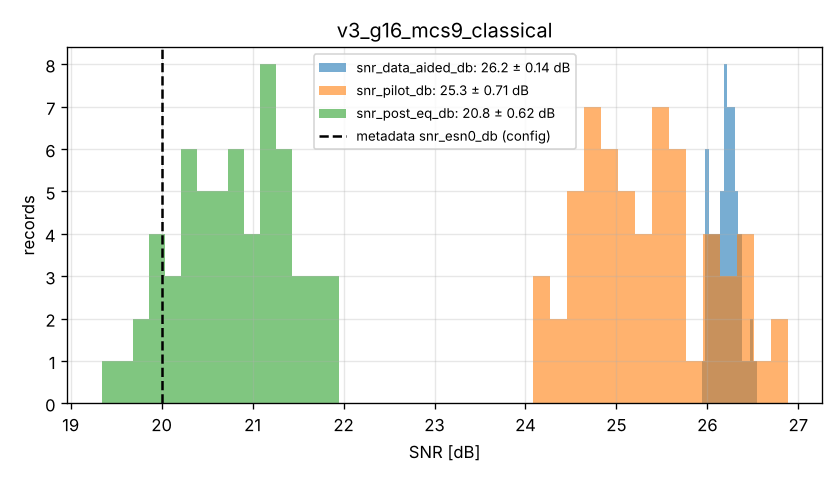

In [11]:
import operating_point
from IPython.display import Markdown
_ = operating_point.run(RUN, "results")
from IPython.display import Image; Image("results/v3_g16_mcs9_classical_snr_hist.png", width=600)

### Task 5 — Visual sanity check
Left: constellation, coloured by OFDM symbol. With the gNB estimate the clusters **rotate with symbol index**:
the gNB holds one estimate over many symbols while a residual frequency offset slowly turns the phase. The Python
receiver interpolates linearly in time and removes most of that.
Middle: |H| and phase per DMRS symbol — the channel is nearly flat (≈1 dB ripple) with a linear phase (timing offset).
Right: the grid as stored vs. unpacked.

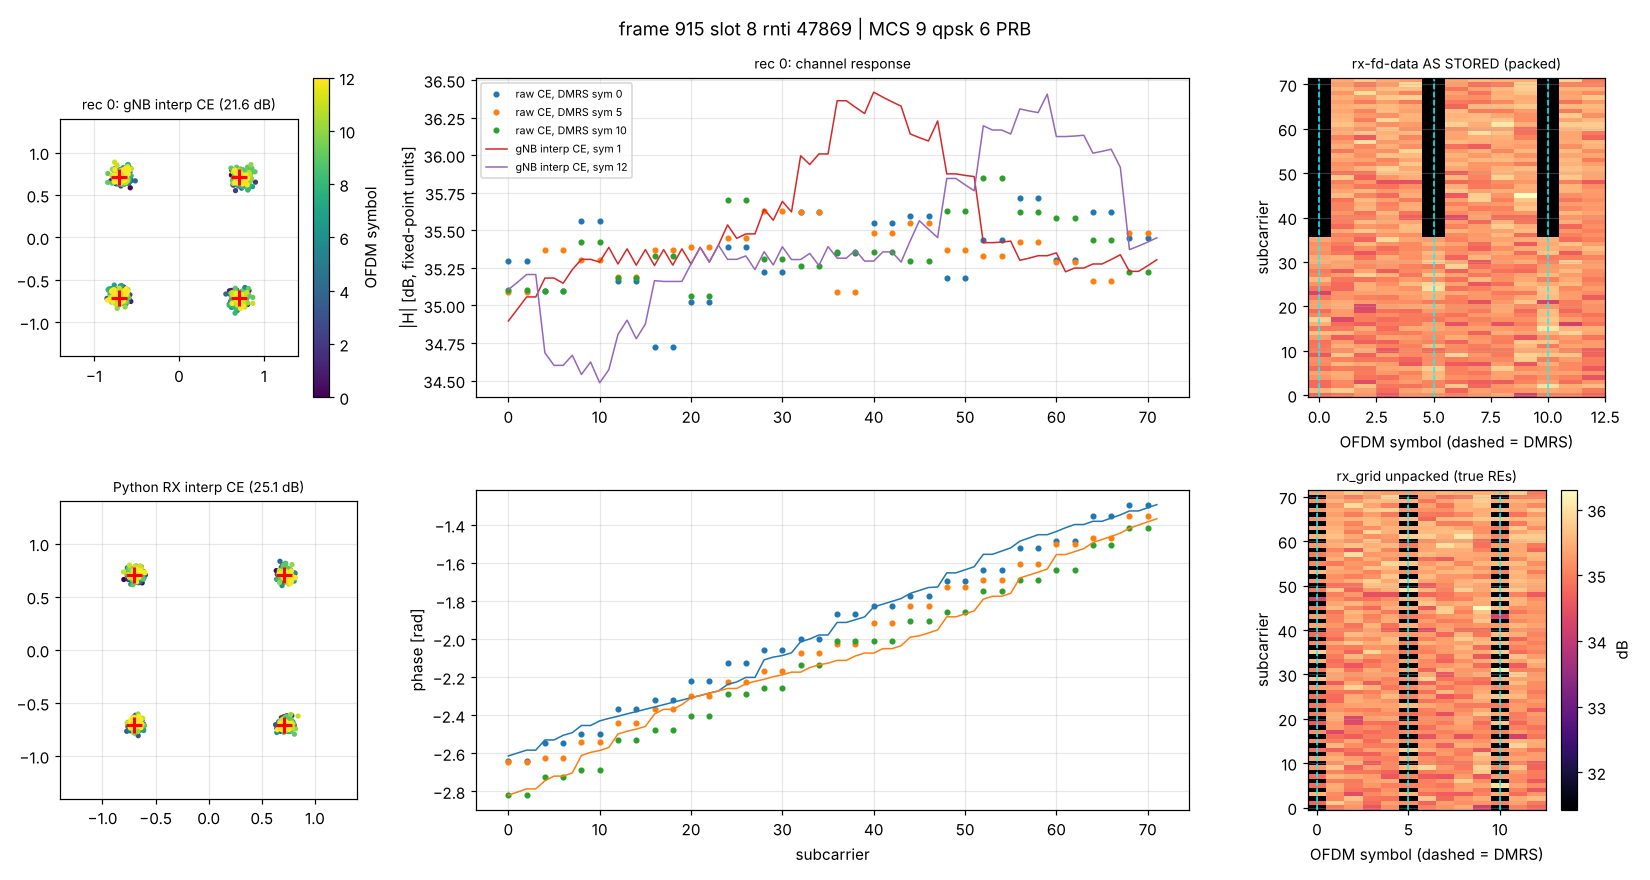

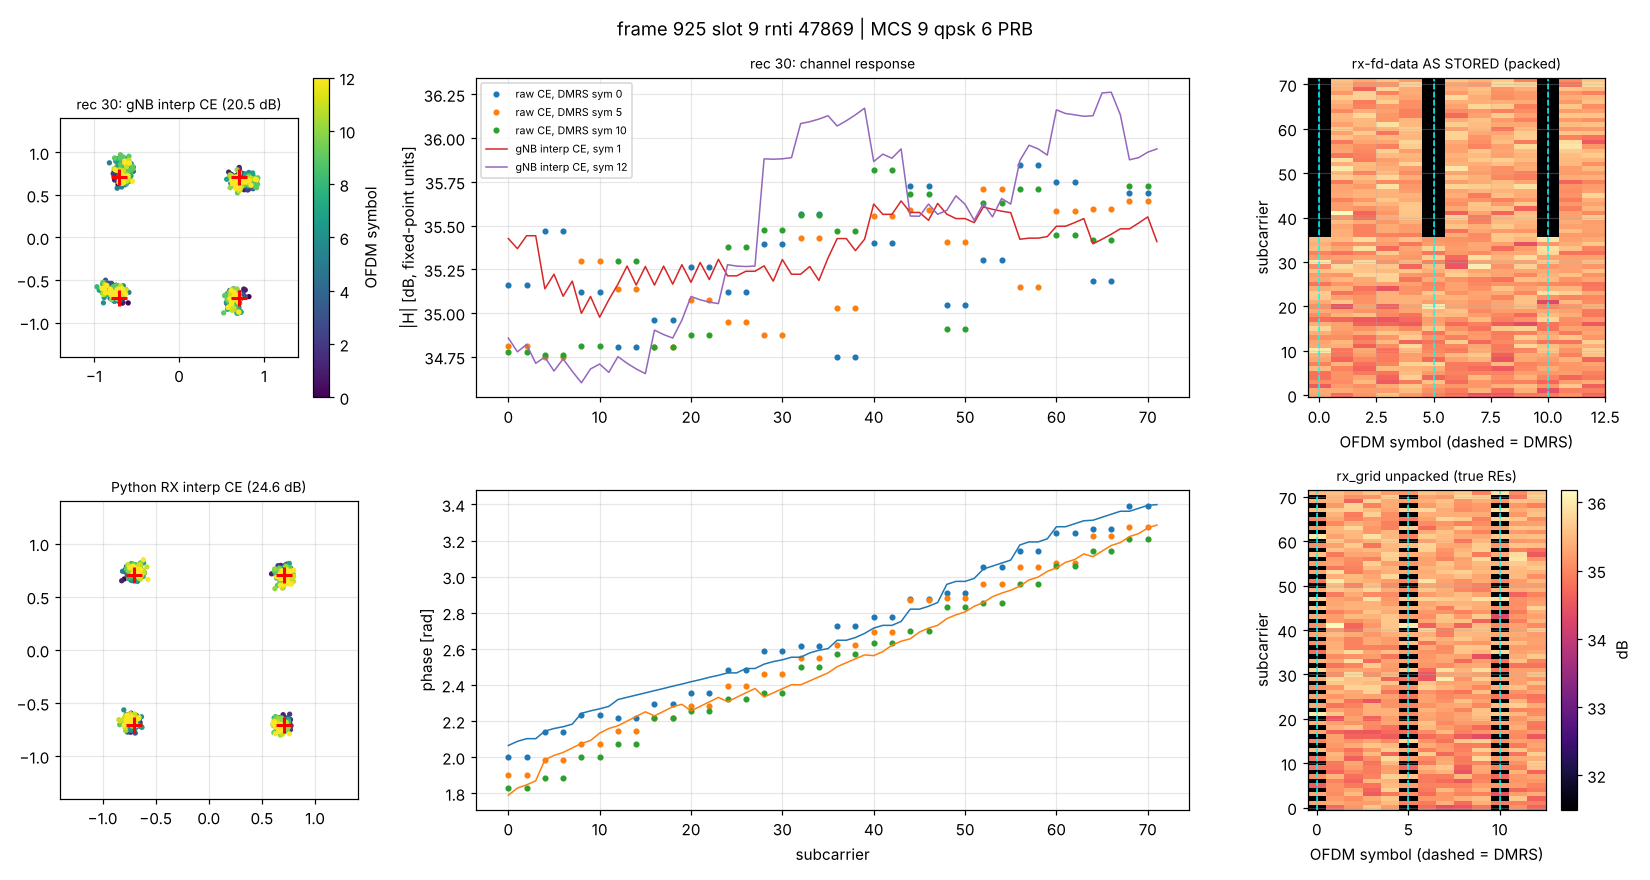

In [12]:
import plots
for rid in (0, 30):
    p = plots.plot_record(recs[rid], "results/plots")
    display(Image(p, width=1000))

### Task 4 — Channel features
Per slot: SNR, time correlation between DMRS symbols (Doppler), residual CFO, frequency correlation, timing offset,
RMS delay spread, and magnitude variation. `records_needed_95pct` = records needed for the mean to fall within the
stated tolerance at 95 % confidence, N = (1.96·σ/tol)².

               feature      mean       std       min       max  tolerance  records_needed_95pct
     snr_data_aided_db     26.21    0.1399     25.94     26.54        0.1                     8
          snr_pilot_db     25.34    0.7083     24.08     26.88        0.1                   193
        snr_post_eq_db      20.8    0.6233     19.34     21.95        0.1                   150
  snr_post_eq_blind_db      20.8    0.6233     19.34     21.95        0.1                   150
             rho_t_0_5    0.9987  0.000281    0.9978    0.9993     0.0001                    31
            rho_t_5_10    0.9987 0.0003273    0.9979    0.9994     0.0001                    42
            rho_t_mean    0.9987 0.0002477    0.9982    0.9992     0.0001                    24
       rho_t_mean_corr         1  0.000235    0.9997     1.001     0.0001                    22
            doppler_hz     3.995     8.178         0     28.95          5                    11
doppler_hz_uncorrected     64.01     6.2

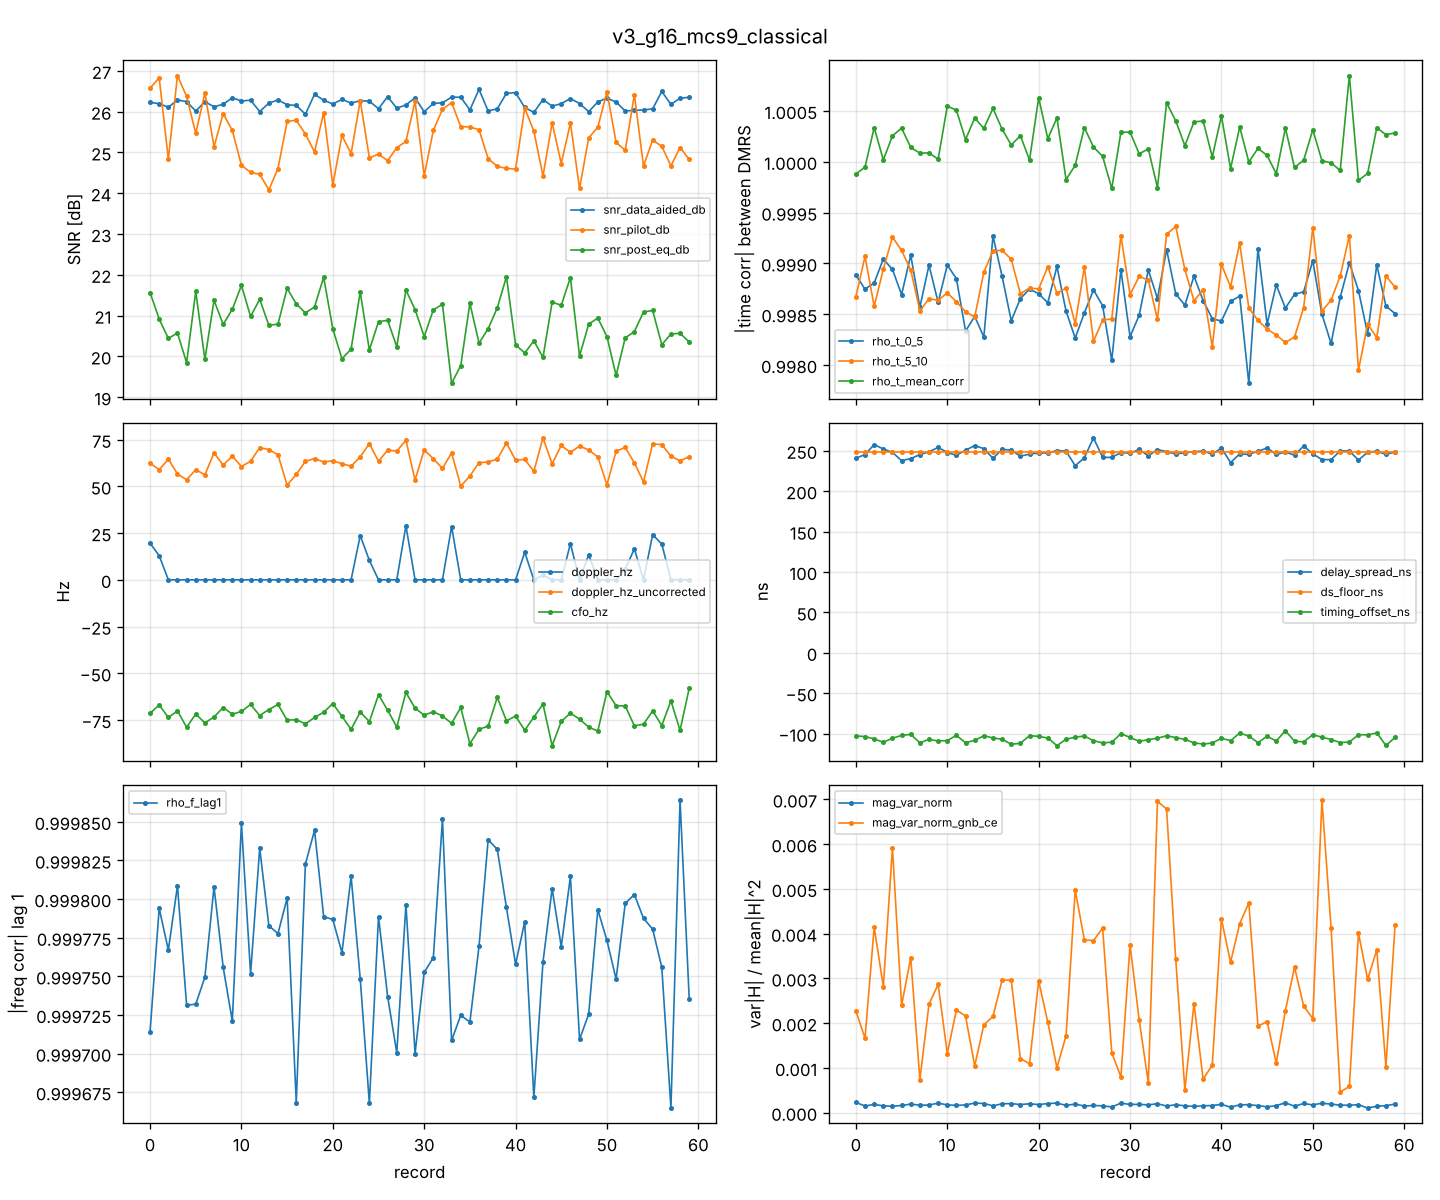

In [13]:
import channel_features as cf
feats = cf.run(RUN, "results")
display(Image("results/v3_g16_mcs9_classical_features.png", width=1000))

**How to read these numbers**

* **Delay spread is not measurable here.** Apparent RMS ≈ 247 ns equals the value the same method gives for a
  perfectly *flat* channel (249 ns): it is the window / resolution floor. Resolution is 1/(72 × 30 kHz) = 463 ns,
  so a 50 ns TDL channel is invisible at 6 PRB. Delay spread needs a wider allocation (≥ ~50 PRB for ~50 ns),
  or must come from the emulator configuration as a label.
* **Doppler is not measurable either.** The raw |ρ| between DMRS symbols ≈ 0.9987 would map to ~64 Hz. But the
  raw CE itself has an SNR of about 28 dB, and that noise alone lowers |ρ| by ~1/SNR ≈ 0.0013. After that
  correction ρ ≈ 1.000 and the Doppler estimate is 4 ± 8 Hz (mostly clamped at 0). At 178 µs DMRS spacing, a 60 Hz
  Doppler only gives 1 − ρ ≈ 0.0013, so a single slot cannot separate it from noise. Doppler estimates need either
  lower noise (more slots averaged, ≥ ~25–50 records per operating point) or longer time lags (correlate across slots).
* **What *is* measurable:** a stable residual CFO of ≈ −73 Hz (the phase drift between DMRS symbols, σ ≈ 6 Hz) and
  a timing offset of ≈ −107 ns (the phase slope across subcarriers). Both are useful features, and both are things
  the receiver must track.
* The channel SNR is very stable (σ 0.14 dB); the blind and post-eq SNR vary more because they include
  estimation noise from a single slot.

In [14]:
pd.read_csv("results/v3_g16_mcs9_classical_feature_stability.csv").round(5)

,feature,mean,std,min,max,tolerance,records_needed_95pct
0,snr_data_aided_db,26.20656,0.13989,25.93577,26.54414,0.10000,8
1,snr_pilot_db,25.34057,0.70833,24.08112,26.88261,0.10000,193
2,snr_post_eq_db,20.79551,0.62333,19.33935,21.95061,0.10000,150
3,snr_post_eq_blind_db,20.79551,0.62333,19.33935,21.95061,0.10000,150
4,rho_t_0_5,0.99867,0.00028,0.99782,0.99927,0.00010,31
5,rho_t_5_10,0.99873,0.00033,0.99795,0.99936,0.00010,42
6,rho_t_mean,0.99870,0.00025,0.99819,0.99921,0.00010,24
7,rho_t_mean_corr,1.00018,0.00023,0.99974,1.00085,0.00010,22
8,doppler_hz,3.99521,8.17827,0.00000,28.95074,5.00000,11
9,doppler_hz_uncorrected,64.01014,6.26931,50.12473,75.93667,5.00000,7


### Task 6 — Python classical reference receiver
Uses only `rx-fd-data` + `raw-ce-fd-data`: deduplicate pair-held pilots → remove the linear phase → linear
interpolation in frequency → linear interpolation in time → ZF → max-log QPSK LLRs → hard decisions vs
`tx-scrambled-bits`.

Why the gNB's estimate loses ~5 dB: it is piecewise **constant in time**. Each DMRS estimate is held over its
neighbouring symbols (1–4, 6–8 and 9–12 share one estimate each), so the CFO phase drift inside each segment is not
tracked. It is also step-shaped across frequency. Linear interpolation in time recovers ~4 dB of that loss.

In [15]:
import classical_rx as crx
res = crx.run(RUN, "results", "linear")
h = r["ce_interp"]
print("\ngNB interp CE: symbol pairs with identical estimates ->",
      [(a, b) for a in range(13) for b in range(a+1, 13) if np.any(h[:, a]) and np.allclose(h[:, a], h[:, b])][:12], "…")

Run v3_g16_mcs9_classical  (60 records, 99360 coded bits, time interpolation = linear)
  Python RX (raw CE + own interp)    coded BER 0.00e+00  (< 3.0e-05 @95%)   post-eq SNR 24.93 ± 0.26 dB
  gNB interpolated CE                coded BER 0.00e+00  (< 3.0e-05 @95%)   post-eq SNR 20.80 ± 0.62 dB
  genie smoothed channel             coded BER 0.00e+00  (< 3.0e-05 @95%)   post-eq SNR 26.55 ± 0.14 dB
  NMSE  py vs gNB CE   -22.32 dB
  NMSE  py vs genie    -29.94 dB
  NMSE  gNB vs genie   -22.24 dB

gNB interp CE: symbol pairs with identical estimates -> [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4), (6, 7), (6, 8), (7, 8), (9, 11), (9, 12), (11, 12)] …


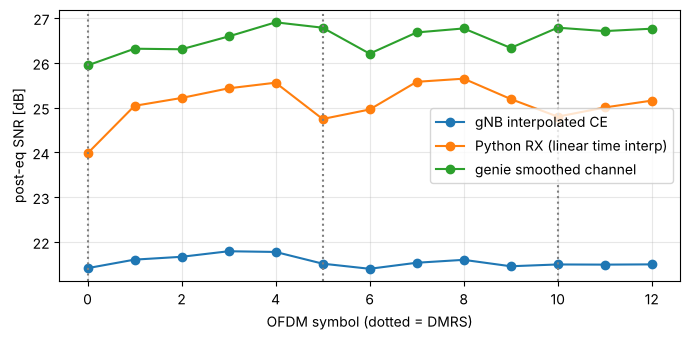

In [16]:
# per-symbol post-equalization SNR, averaged over all records
def per_symbol_snr(H_fn):
    acc = np.zeros(13)
    for q in recs:
        m = q["data_mask"]; xg = dsp.to_grid(dsp.tx_symbols(q), m); H = H_fn(q)
        for s in range(13):
            k = m[:, s]; zz = q["rx_grid"][k, s] / H[k, s]; x_ = xg[k, s]
            a = np.vdot(x_, zz) / np.vdot(x_, x_); acc[s] += np.mean(np.abs(zz - a * x_)**2) / abs(a)**2
    return -10 * np.log10(acc / len(recs))
plt.figure(figsize=(7, 3.5))
for fn, lab in [(lambda q: q["ce_interp"], "gNB interpolated CE"), (lambda q: crx.interpolate_ce(q), "Python RX (linear time interp)"),
                (lambda q: dsp.snr_data_aided(q)["h_smooth"], "genie smoothed channel")]:
    plt.plot(per_symbol_snr(fn), "o-", label=lab)
for s in recs[0]["ul_dmrs_symb_pos"]: plt.axvline(s, color="gray", ls=":")
plt.xlabel("OFDM symbol (dotted = DMRS)"); plt.ylabel("post-eq SNR [dB]"); plt.legend(); plt.tight_layout()

## Part D — Using this data to train a receiver

### D.1 What a training sample looks like
`pack_dataset.py` turns any number of runs into one NPZ (schema in `DATASET_SCHEMA.md`):

| array | shape | meaning |
|---|---|---|
| `inputs` | (N, 72, 13, 4) float32 | [Re y, Im y, Re Ĥ_p, Im Ĥ_p]; y = received grid at true REs (zeros on DMRS REs), Ĥ_p = raw pilot CE (zeros elsewhere); each normalized per sample |
| `labels_grid` | (N, 72, 13, Qm) uint8 | coded bits on their REs (0 on non-data REs) |
| `labels_flat` | (N, n_bits) | the same bits in 3GPP order → can go straight to a descrambler + LDPC decoder |
| `data_mask`, `pilot_mask` | (N, 72, 13) bool | which REs are data / DMRS — use `data_mask` to mask the loss |
| `run_id`, `split`, `meta_*` | (N,) | provenance; the split is **by run** |

A neural receiver (e.g. a small ResNet over the grid, as in DeepRx / NVIDIA's NRX) maps `inputs` → per-RE LLRs
of shape (72, 13, Qm) and is trained with **binary cross-entropy on `labels_grid`, masked by `data_mask`**.
Because the labels are the scrambled coded bits, the trained model slots in exactly where the classical
demapper sits, and the existing descrambler + LDPC decoder stay untouched.

In [17]:
d = np.load("results/dataset_v3_g16_mcs9_classical.npz")
for k in ["inputs", "labels_grid", "labels_flat", "data_mask", "pilot_mask", "split", "run_id"]:
    print(f"{k:<12} {str(d[k].shape):<18} {d[k].dtype}")
# the label check: the packed labels agree with the gNB's own equalized constellation
i = 7; m = d["data_mask"][i]
y = d["inputs"][i, ..., 0] + 1j * d["inputs"][i, ..., 1]
zz = dsp.data_res(y, m) / dsp.data_res(recs[i]["ce_interp"], m)
print("label/constellation agreement:", np.mean(np.stack([zz.real < 0, zz.imag < 0], 1).ravel() == d["labels_flat"][i, :1656]))

inputs       (60, 72, 13, 4)    float32
labels_grid  (60, 72, 13, 2)    uint8
labels_flat  (60, 1656)         uint8
data_mask    (60, 72, 13)       bool
pilot_mask   (60, 72, 13)       bool
split        (60,)              <U5
run_id       (60,)              <U21
label/constellation agreement: 1.0


### D.2 The metric a neural receiver will be judged on
Besides coded BER / BLER after LDPC, the natural metric is the **binary cross-entropy (BCE) of the LLRs** against the
labels: it is the training loss, it rewards LLRs that are confident *and* correct, and it is related to the achievable
rate (1 − BCE ≈ bit-metric-decoding rate per bit). On this run at 26 dB, all baselines have BCE ≈ 0 (no errors, huge
LLRs), so neither BER nor BCE separates receivers. The noise sweep in D.3 brings both into a useful range.

In [18]:
def bce(llr, bits):
    "BCE in bit/bit; LLR>0 <=> bit 0, so p(bit=1) = sigmoid(-llr)"
    return np.mean(np.logaddexp(0, -llr * (1 - 2 * bits.astype(float)))) / np.log(2)

### D.3 Semi-synthetic augmentation: BER curves from real channels
To get errors out of an error-free capture, we can add complex Gaussian noise to the measured grid. The noise is
added to y and, consistently, to the pilot estimate (variance σ²/|x_p|², halved for OAI's pair averaging), and we
sweep the SNR. "genie channel" uses the noise-free smoothed channel (perfect CSI). This keeps the real hardware impairments (CFO, timing, IQ, phase noise) and creates the low-SNR
regime that training needs. It is a stop-gap until the emulator sweep arrives, not a replacement for it.

,SNR dB,BER Python RX,BER genie channel,BCE Python RX,BCE genie channel
0,-2,0.26318,0.21372,0.81615,0.66995
1,0,0.20042,0.16136,0.68424,0.53983
2,2,0.13385,0.10401,0.49857,0.37364
3,4,0.07958,0.05659,0.31829,0.21860
4,6,0.03680,0.02376,0.15865,0.09685
5,8,0.01149,0.00611,0.05134,0.02476
6,10,0.00251,0.00090,0.01165,0.00374
7,12,0.00021,0.00004,0.00102,0.00013


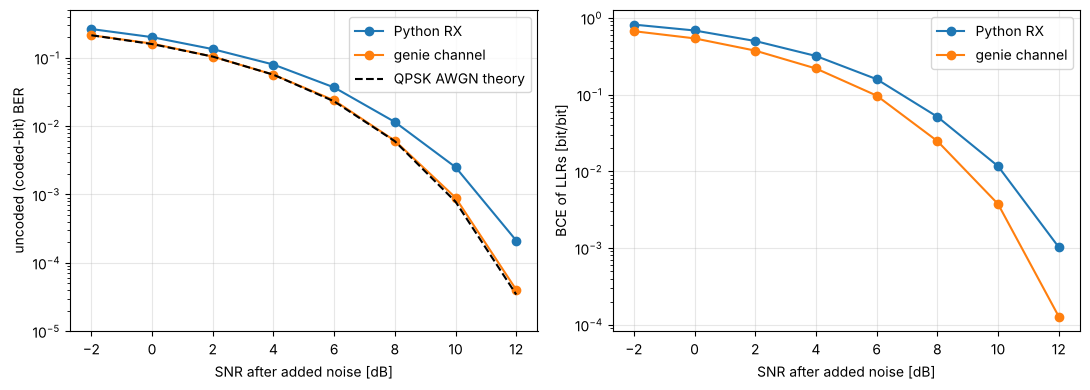

In [19]:
rng = np.random.default_rng(0)
def degrade(q, snr_db):
    q = dict(q); m = q["data_mask"]; pm = q["pilot_mask"]
    sig = dsp.snr_data_aided(q)["signal_power"]
    nv = sig / 10 ** (snr_db / 10)
    n = (rng.standard_normal(q["rx_grid"].shape) + 1j * rng.standard_normal(q["rx_grid"].shape)) * np.sqrt(nv / 2)
    q["rx_grid"] = np.where(m, q["rx_grid"] + n, 0)
    ce_scale = np.abs(q["ce_pilots"][pm]).mean() / np.sqrt(sig)                          # fixed-point scale of CE vs y
    npil = (rng.standard_normal(pm.sum()) + 1j * rng.standard_normal(pm.sum())) * np.sqrt(nv / 4) * ce_scale
    ce = q["ce_pilots"].copy(); vals = ce[pm]
    # keep OAI's pair-holding structure: same noise on both members of a pair
    npil = np.repeat(npil[0::2], 2)[:vals.size]
    ce[pm] = vals + npil; q["ce_pilots"] = ce
    return q
snrs = np.arange(-2, 13, 2)
rx_paths = {"Python RX": lambda q, qq: crx.interpolate_ce(qq),
            "genie channel": lambda q, qq: dsp.snr_data_aided(q)["h_smooth"]}
ber = {k: [] for k in rx_paths}; bces = {k: [] for k in rx_paths}
for s in snrs:
    e = {k: 0 for k in rx_paths}; b = {k: [] for k in rx_paths}; nb = 0
    for q in recs:
        qq = degrade(q, s); lab = qq["tx_coded"]; nb += lab.size
        for k, Hf in rx_paths.items():
            llr, hb, _ = crx.demodulate(qq, Hf(q, qq))
            e[k] += np.sum(hb != lab); b[k].append(bce(llr, lab))
    for k in rx_paths:
        ber[k].append(e[k] / nb); bces[k].append(np.mean(b[k]))
from math import erfc, sqrt
theory = [0.5 * erfc(sqrt(10 ** (s / 10) / 2)) for s in snrs]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in rx_paths:
    ax[0].semilogy(snrs, np.maximum(ber[k], 1e-6), "o-", label=k); ax[1].semilogy(snrs, bces[k], "o-", label=k)
ax[0].semilogy(snrs, theory, "k--", label="QPSK AWGN theory"); ax[0].set_ylim(1e-5, 0.5)
ax[0].set_ylabel("uncoded (coded-bit) BER"); ax[1].set_ylabel("BCE of LLRs [bit/bit]")
for a in ax: a.set_xlabel("SNR after added noise [dB]"); a.legend()
plt.tight_layout(); plt.savefig("results/plots/augmented_ber_bce.png", dpi=120)
pd.DataFrame({"SNR dB": snrs, **{f"BER {k}": ber[k] for k in rx_paths}, **{f"BCE {k}": bces[k] for k in rx_paths}}).round(5)

### D.4 What this run can and cannot be used for

**Can:** build and validate the whole pipeline (loading, labels, alignment, packing, baselines); check that labels line
up with the constellation; get real-hardware impairments (CFO, timing) into augmentation.

**Cannot:** train or evaluate a model on its own. It is one MCS, one strong static link, and 60 slots with zero errors,
so a model would just learn the identity. Doppler and delay spread are not identifiable at this bandwidth and SNR.

### D.5 Requests for the next captures
1. **Confirm the setup**: emulator (TDL-D, 5 m/s, 50 ns, 20 dB per metadata) or cable + attenuator (per task sheet)? The
   measured SNR (26 dB) matches neither assumption cleanly. Record the *actual* channel parameters per run.
2. **Sweep SNR down to the waterfall** (≈ −2 … 10 dB for QPSK MCS 9) so there are real decoding errors, plus other MCS.
3. **Wider allocation** (≥ 25–50 PRB) if delay spread is a feature of interest; more slots per point for Doppler.
4. If possible, also record the **received DMRS REs** (currently zeroed in `rx-fd-data`) and the gNB's **LLRs**
   (to compare a neural demapper directly against OAI's).
5. Fix or drop `payload_bit_pattern = "zeros"` (the payload is not all zeros).
6. Keep one run per folder, so the train/test split can be done **by run** (`pack_dataset.py --test-runs …`).